# SOCAR Hackathon 2026 — Phase 2: Pressure Transient Analysis

Six shut-ins, six build-ups. For each one: permeability, skin, ΔP_skin and the Horner slope,
computed on the oil rate predicted in Phase 1, as the brief requires.

**Result: 8.3840 / 20 on the leaderboard, the best of the PTA submissions.**

The submitted answer is an **exact model match**. The radial diffusivity equation, with wellbore
storage, skin and an outer boundary, is solved in Laplace space and fitted to every point of each
build-up. The Horner straight line is computed alongside it as the textbook reference.

This notebook rebuilds the submitted file from the 1-minute gauge data. It also shows the evidence
behind each choice, including two checks on data the fit never saw:
- a forecast of the late build-up from its early part;
- an alternative boundary that the data reject.

## Setup

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for p in ("ml/src", "ml/eda", "ml"):
    sys.path.insert(0, str(ROOT / p))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

import viz
import pta_model as PM       # diffusivity equation: Laplace solutions, Stehfest inversion, least-squares fit
import pta_explore as X      # data access, Horner windows, figures (loads the 1-minute gauge data)
import make_pta as MP        # builds and checks the submitted file

try:
    from IPython.display import display
except ImportError:          # plain-Python check run
    display = print

def show(fig, path=None):
    # pta_explore saves its figures to ml/outputs/figures/pta/; here they are shown inline instead
    fig.tight_layout(rect=(0, 0, 1, getattr(fig, "_viz_top", 0.95)))
    display(fig)
    plt.close(fig)

viz.save = show
viz.apply_style()
print(f"{len(X.HF):,} gauge readings loaded")

3,914,560 gauge readings loaded


## 1. The build-ups

A build-up exists only where the choke closes: `choke_opening_pct = 0` in `choke_events.csv`,
which also stops gas lift. That gives six events on six wells. GL-03, GL-05, GL-07 and GL-09
never shut in, so no PTA is possible on them.

In [2]:
ev = X.shut_in_events()
evd = {e.well: e for e in ev.itertuples()}
rows = []
for e in ev.itertuples():
    r, _ = X.interpret(e, "T1", "B")
    rows.append(dict(well=e.well, shut_in=e.start, reopened=e.end, duration_h=r["duration_h"],
                     pwf_at_shut_in_psia=r["pwf_gauge_psia"], last_pressure_psia=r["p_end_gauge_psia"],
                     build_up_psi=round(r["p_end_gauge_psia"] - r["pwf_gauge_psia"], 1)))
pd.DataFrame(rows)

,well,shut_in,reopened,duration_h,pwf_at_shut_in_psia,last_pressure_psia,build_up_psi
0,GL-01,2025-04-15 08:00:00,2025-04-18 08:00:00,71.98,3240.719971,3511.520020,270.799988
1,GL-02,2025-03-08 14:23:00,2025-03-08 20:02:00,5.63,2884.100098,3164.860107,280.799988
2,GL-04,2025-06-03 08:00:00,2025-06-05 08:00:00,47.98,2307.419922,3144.810059,837.400024
3,GL-06,2025-07-22 03:11:00,2025-07-22 11:11:00,7.98,2680.080078,2799.439941,119.400002
4,GL-08,2025-08-19 09:00:00,2025-08-22 09:00:00,71.98,2636.760010,3158.489990,521.700012
5,GL-10,2025-05-27 21:04:00,2025-05-28 06:04:00,8.98,3685.429932,3913.639893,228.199997


## 2. Inputs

**Rate.** q is the Phase 1 predicted **oil** rate on the last full flowing day before the shut-in.
It comes from the shipped Task 1 file, which scored 21.0200 on the VFM leaderboard.
- k is proportional to q, so the VFM accuracy carries straight into k.
- m and ΔP_skin are set by the pressure data and barely depend on q.

**Producing time.** N_p = cumulative oil at 2025-01-01 + predicted daily oil up to the shut-in.
t_p = 24·N_p/q is the Horner pseudo-producing time.

**Rock and fluid** come from `reservoir_pvt.csv`. Single-phase oil holds, because the downhole
pressure stays above the bubble point on every well.

**Datum.** The gauge sits above the datum. The hydrostatic offset is constant through a build-up,
so it cancels in every pressure difference (checked in section 6).

In [3]:
inp = []
for e in ev.itertuples():
    r, _ = X.interpret(e, "T1", "B")
    P = X.PVT.loc[e.well]
    inp.append(dict(well=e.well, q_oil_stbd=r["qo_stbd"], Np_stb=r["np_stb"], tp_h=r["tp_h"],
                    h_ft=P.net_pay_thickness_ft, phi=P.porosity_frac, ct_per_psi=P.total_compressibility_1_psi,
                    rw_ft=P.wellbore_radius_ft, Bo_rb_stb=P.oil_fvf_rb_stb, mu_cp=P.oil_viscosity_cp,
                    gauge_to_datum_psi=r["datum_offset_psi"]))
pd.DataFrame(inp)

,well,q_oil_stbd,Np_stb,tp_h,h_ft,phi,ct_per_psi,rw_ft,Bo_rb_stb,mu_cp,gauge_to_datum_psi
0,GL-01,991.5,10070739,243769.8,80.0,0.194,0.000013,0.328,1.160,1.054,111.3
1,GL-02,1324.8,11742326,212723.3,82.0,0.173,0.000016,0.328,1.149,1.019,116.6
2,GL-04,792.3,4624719,140089.9,32.0,0.161,0.000012,0.255,1.136,1.725,92.8
3,GL-06,654.1,5072552,186120.2,68.0,0.221,0.000014,0.328,1.120,2.443,123.1
4,GL-08,1453.9,5329626,87977.9,65.0,0.243,0.000012,0.255,1.189,0.919,56.9
5,GL-10,1745.0,15826040,217664.7,136.0,0.222,0.000011,0.328,1.130,2.134,93.2


## 3. How to read a build-up

These are analytical type curves from the same Laplace solutions the fit uses. Each panel shows
Δp and the Bourdet derivative for a different reservoir, and these are the shapes to compare the
real derivatives against:
- **Wellbore storage:** unit slope.
- **IARF:** flat derivative at m/2.303.
- **Closed boundary in a build-up:** the derivative falls towards p̄.
- **Sealing fault:** the derivative doubles.

The second figure shows that skin changes the size of the storage hump but not the IARF level.
This is why k from the IARF level is skin-free.

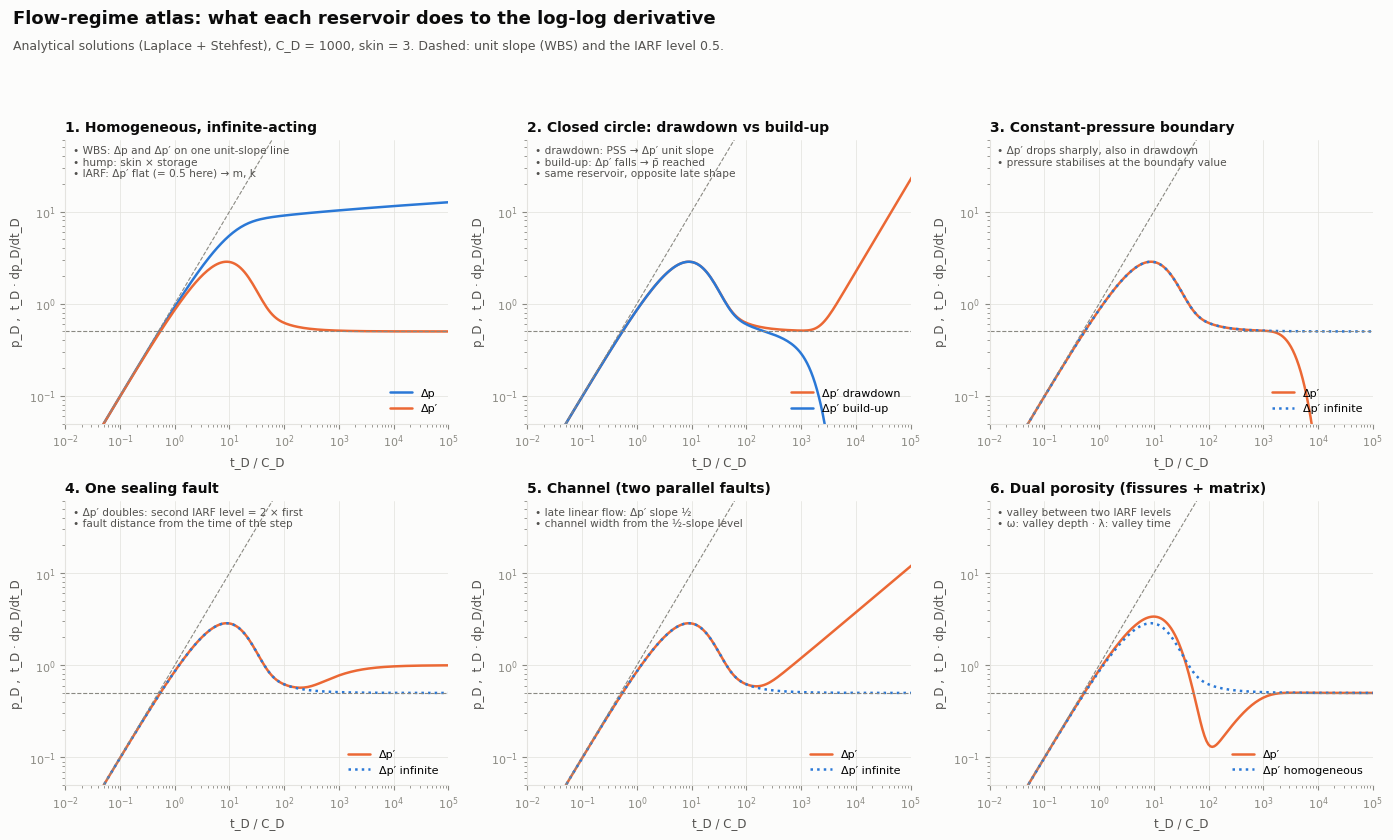

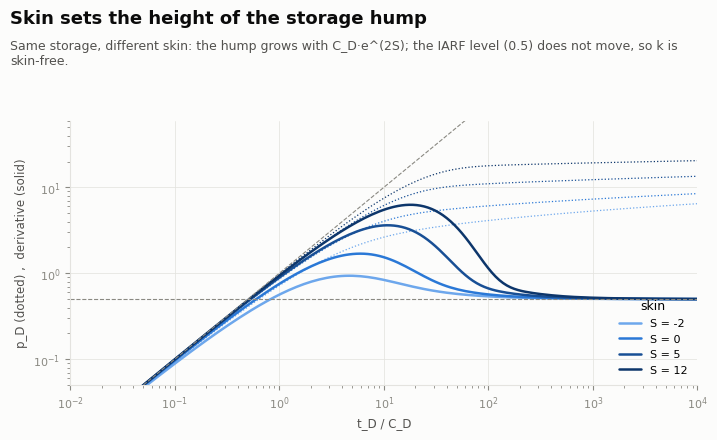

In [4]:
X.theory_figures()

## 4. The six build-ups and the model match

Dots are the measured Δp and Bourdet derivative, on a 40-points-per-log-cycle grid where each
point is the median of the 1-minute readings in its bin. Lines are the fitted model:
wellbore storage + skin + radial flow + boundary.

The boundary is chosen per well:
- the closed circle is kept only when it cuts the misfit by more than 30%, which happens on
  GL-01 and GL-10;
- the other four wells are infinite-acting for the whole test.

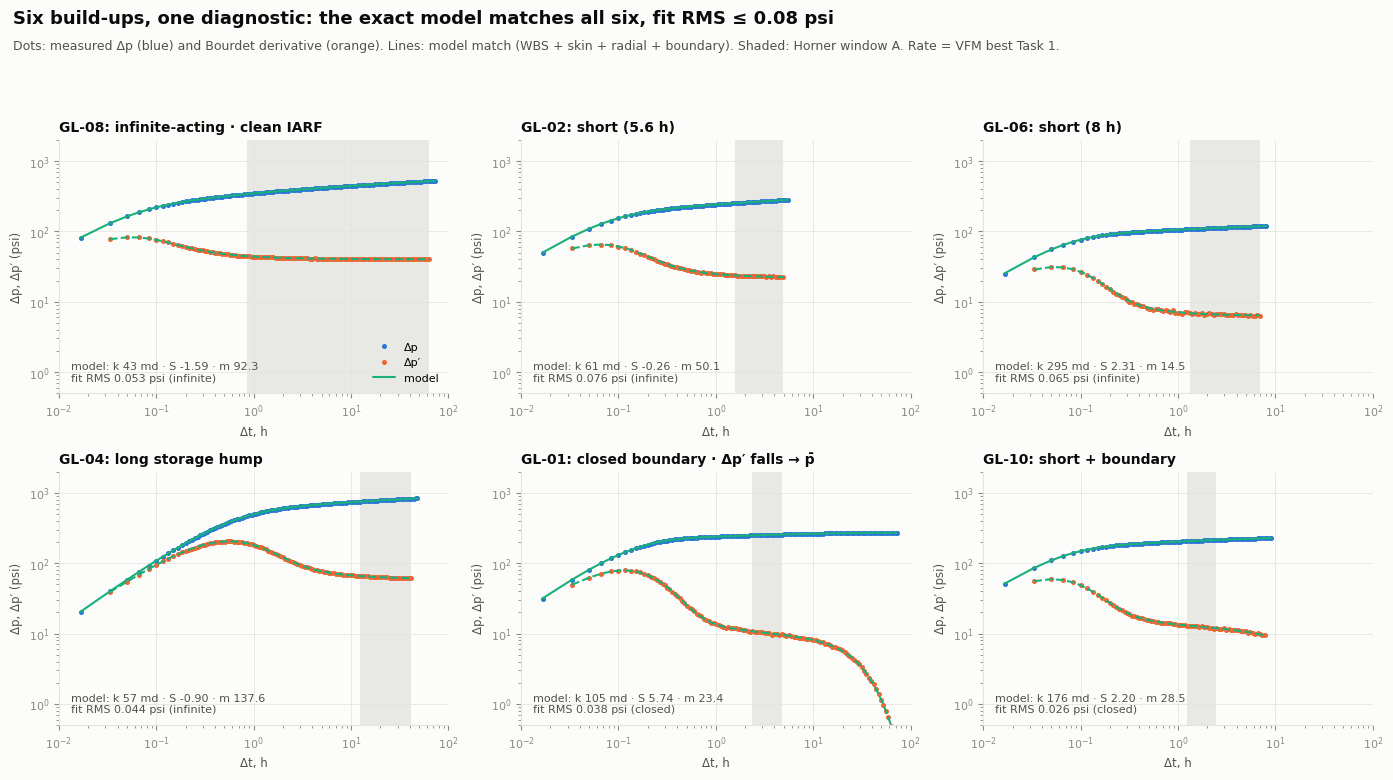

In [5]:
A, B, M, plots, curves = {}, {}, {}, {}, {}
for e in ev.itertuples():
    A[e.well], plots[e.well] = X.interpret(e, "T1", "A")
    B[e.well], _ = X.interpret(e, "T1", "B")
    M[e.well], curves[e.well] = X.model_match(e, "T1")
X.overview_figure(ev, plots, A, M, curves)

Every build-up with all the classic plots:
- **A.** pressure history;
- **B.** Cartesian build-up with the model;
- **C.** log-log diagnostic with the model;
- **D.** Horner plot;
- **E.** MDH plot;
- **F.** results table comparing Horner windows A and B with the model.

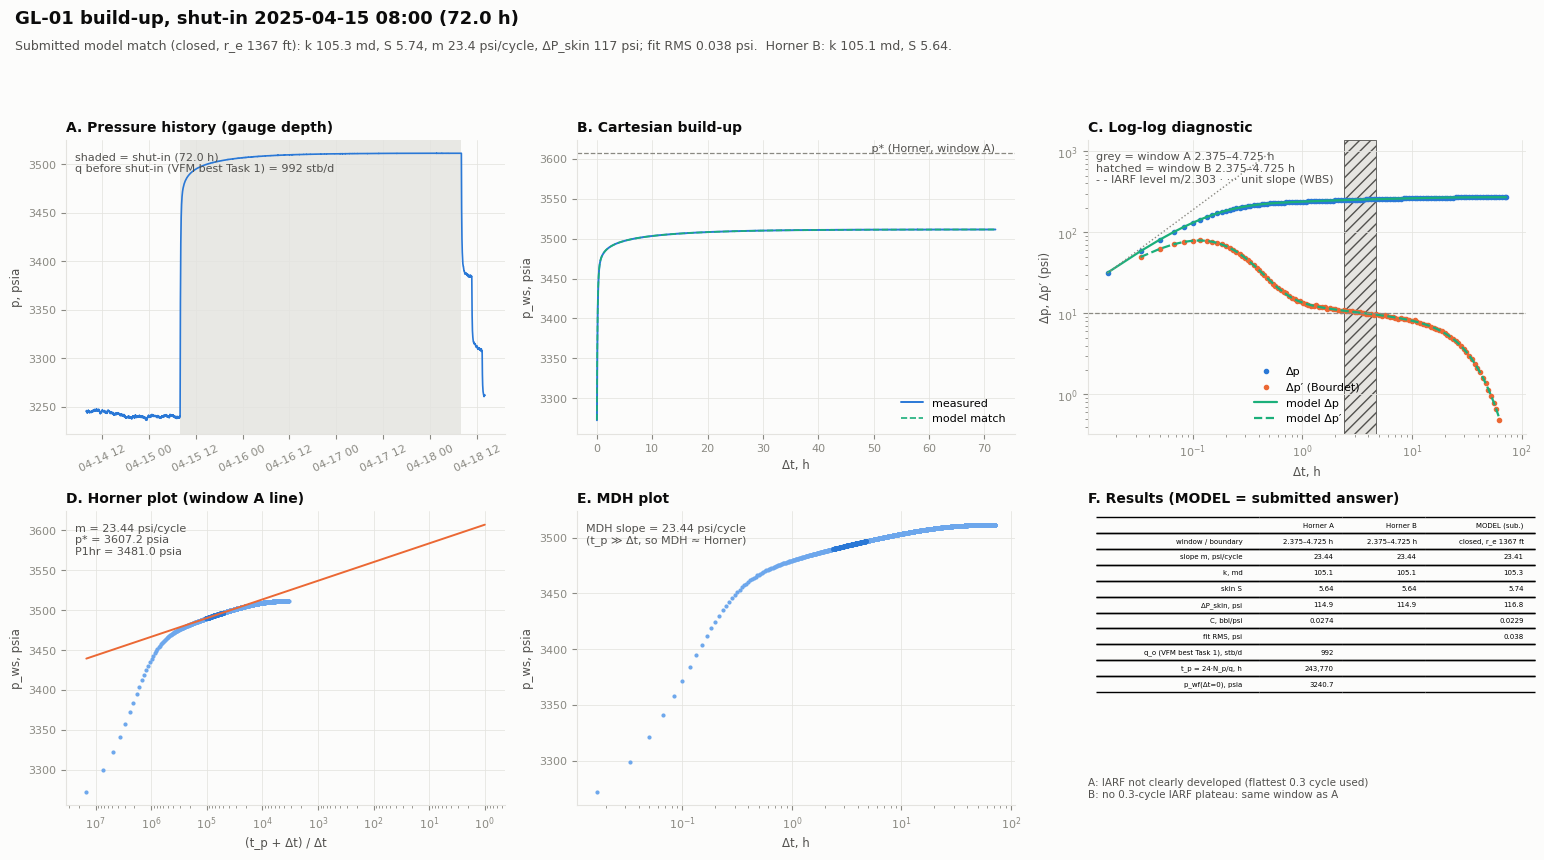

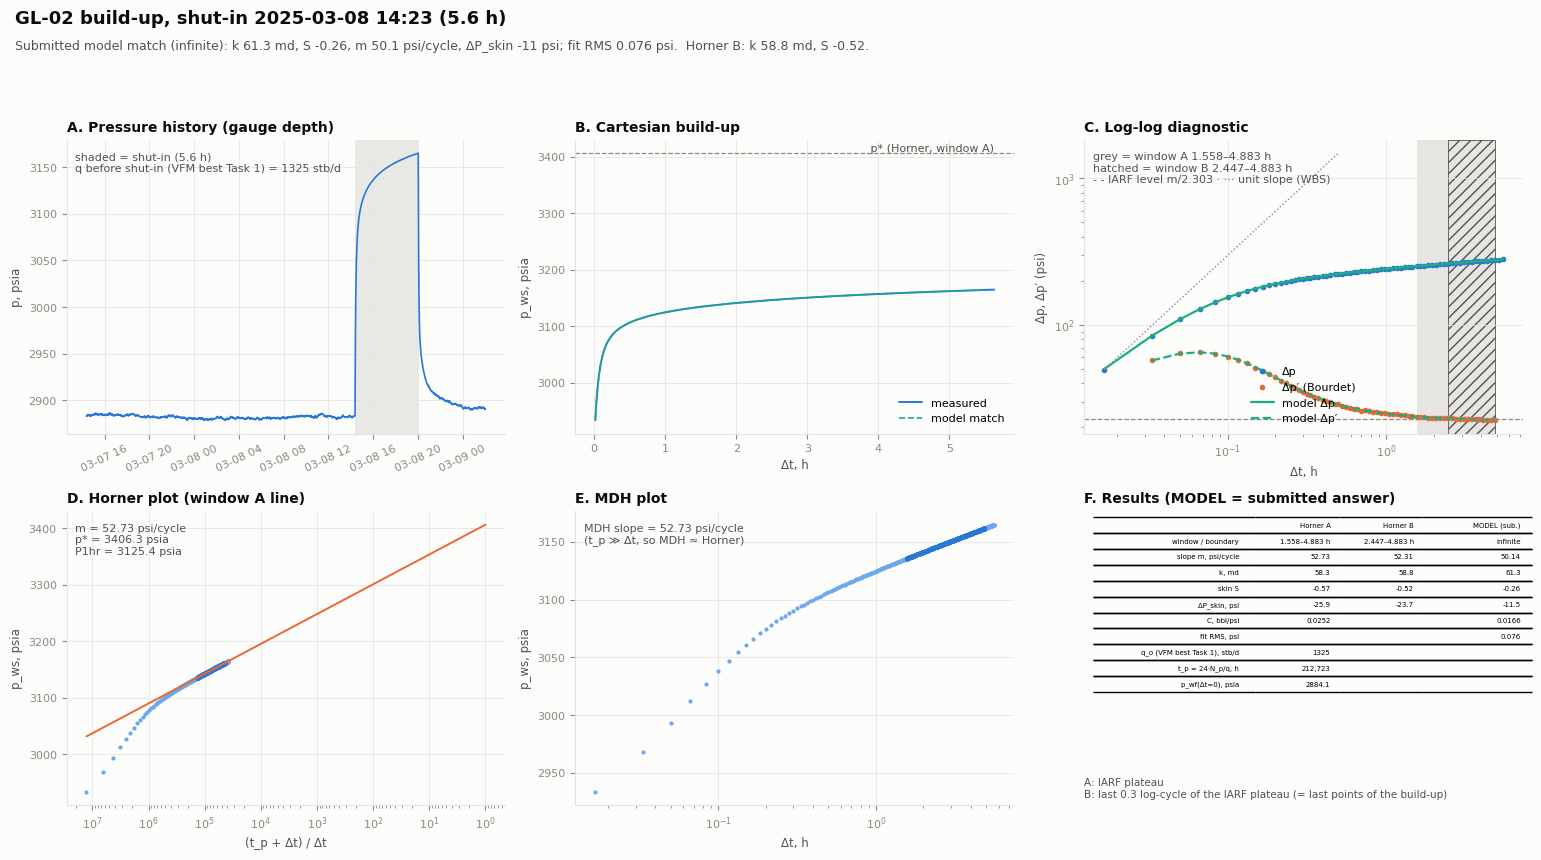

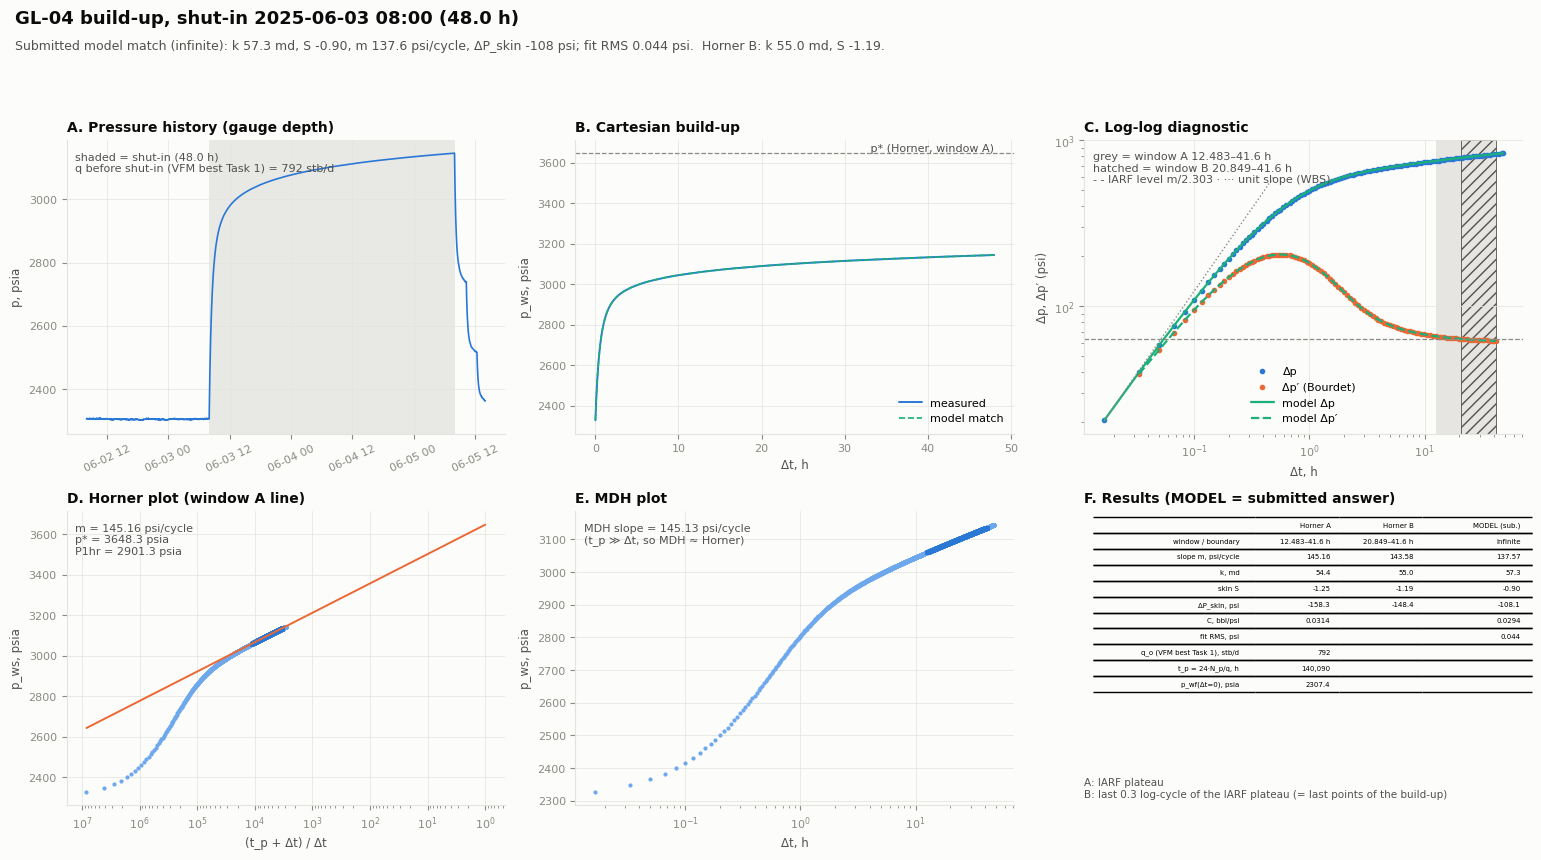

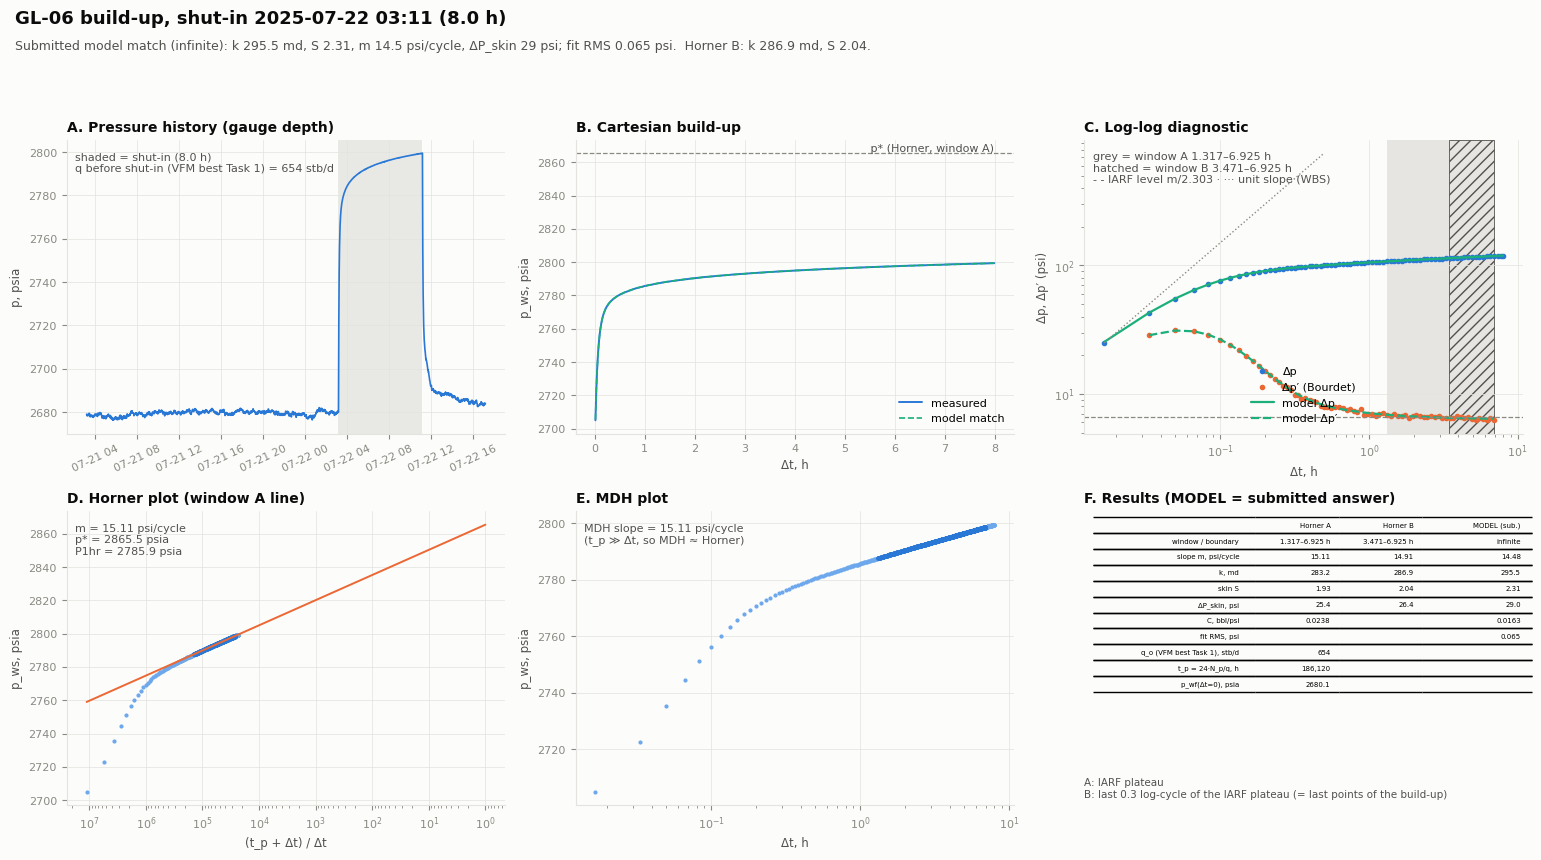

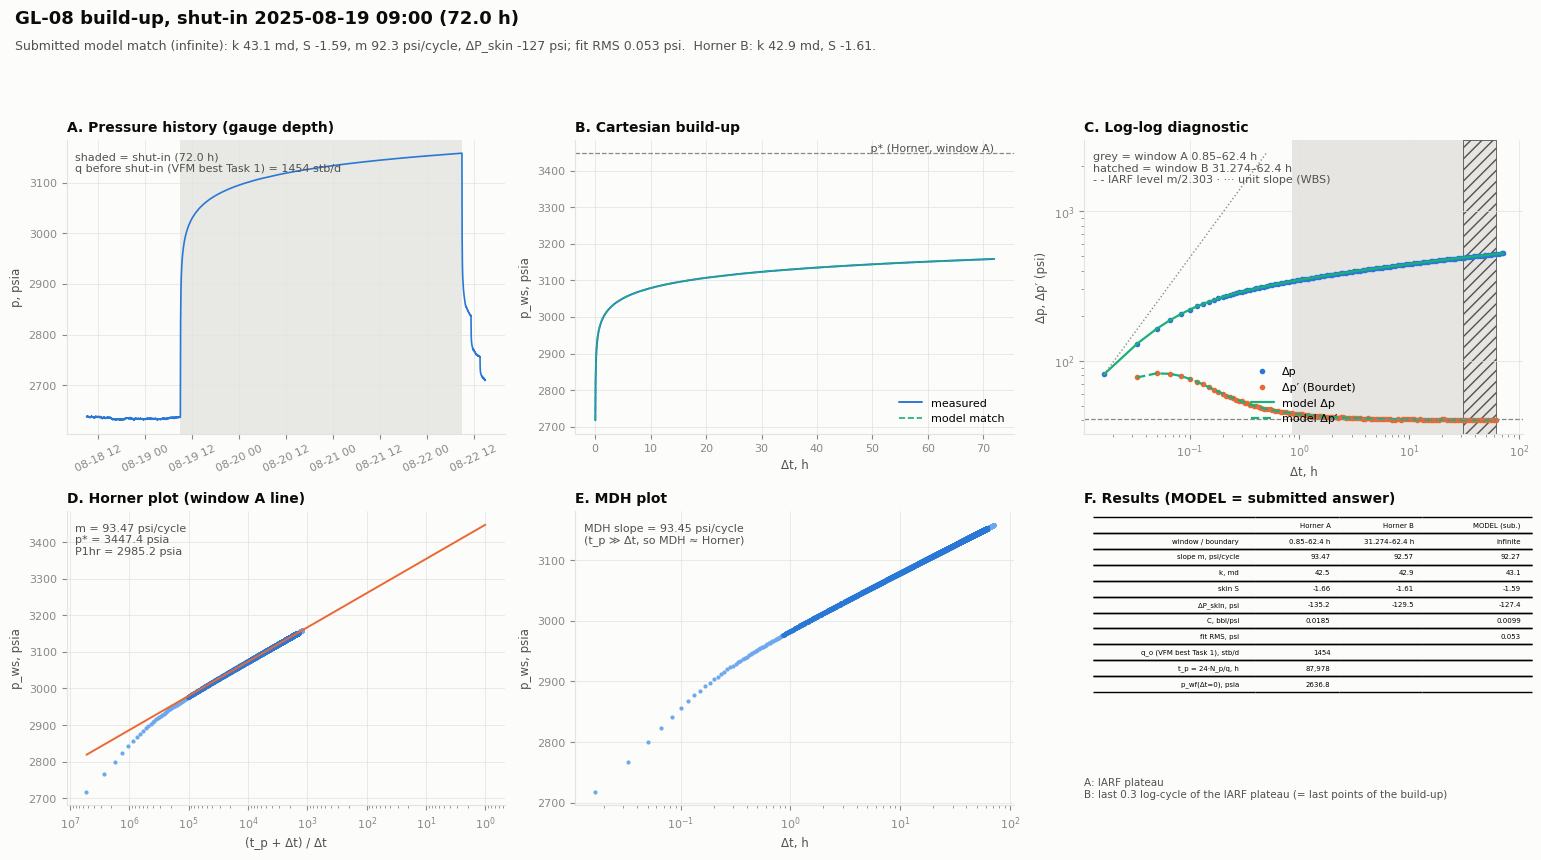

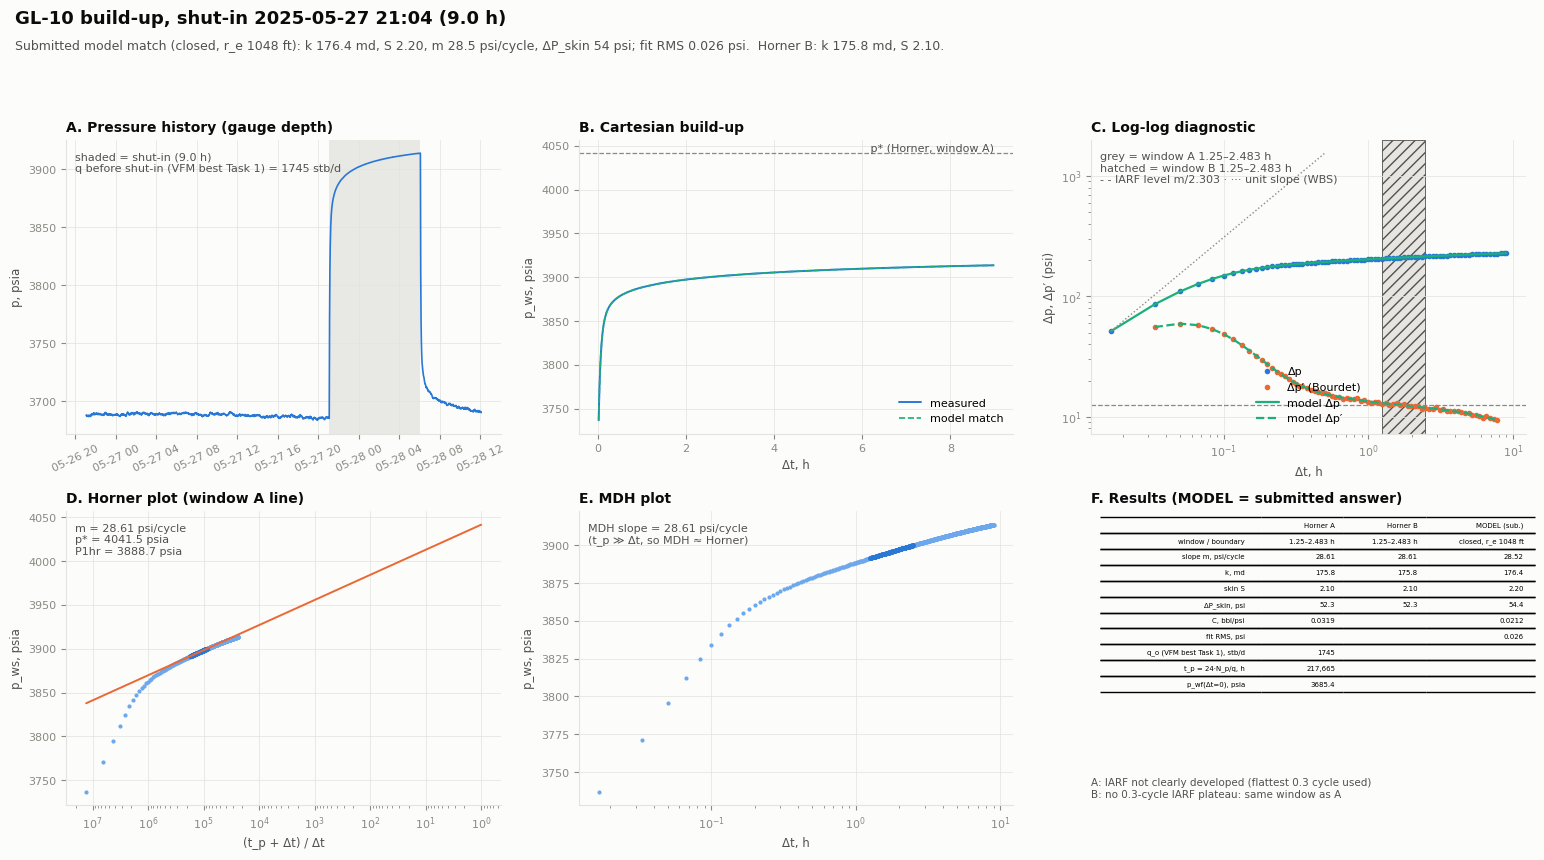

In [6]:
for e in ev.itertuples():
    X.event_figure(e, A[e.well], plots[e.well], B[e.well], M[e.well], curves[e.well])

## 5. Horner straight line vs exact model

The Horner line uses k = 162.6·q·B·μ/(m·h) and
S = 1.151·[(P1hr − p_wf)/m − log10(k/(φ·μ·c_t·r_w²)) + 3.2275]. It is fitted on two windows:
- **Window A:** the IARF plateau, i.e. the longest run where the derivative is flat within ±0.10
  in log-slope.
- **Window B:** the last 0.3 log-cycle of that plateau, the points furthest from wellbore storage.

The model needs no window. It fits every point and reports the slope it implies,
m = 162.6·q·B·μ/(k·h), and ΔP_skin = 0.869·m·S.

In [7]:
cols = ["well_name", "window", "window_start_h", "window_end_h", "horner_slope_psi_per_cycle",
        "permeability_md", "skin", "delta_p_skin_psi", "note"]
pd.concat([pd.DataFrame(A.values()), pd.DataFrame(B.values())])[cols].sort_values(["well_name", "window"]).reset_index(drop=True)

,well_name,window,window_start_h,window_end_h,horner_slope_psi_per_cycle,permeability_md,skin,delta_p_skin_psi,note
0,GL-01,A,2.375,4.725,23.443,105.10,5.642,114.93,IARF not clearly developed (flattest 0.3 cycle...
1,GL-01,B,2.375,4.725,23.443,105.10,5.642,114.93,no 0.3-cycle IARF plateau: same window as A
2,GL-02,A,1.558,4.883,52.734,58.33,-0.566,-25.92,IARF plateau
3,GL-02,B,2.447,4.883,52.310,58.80,-0.522,-23.71,last 0.3 log-cycle of the IARF plateau (= last...
4,GL-04,A,12.483,41.600,145.160,54.35,-1.255,-158.29,IARF plateau
5,GL-04,B,20.849,41.600,143.581,54.95,-1.190,-148.42,last 0.3 log-cycle of the IARF plateau (= last...
6,GL-06,A,1.317,6.925,15.109,283.24,1.931,25.36,IARF plateau
7,GL-06,B,3.471,6.925,14.915,286.93,2.040,26.44,last 0.3 log-cycle of the IARF plateau (= last...
8,GL-08,A,0.850,62.400,93.471,42.52,-1.664,-135.17,IARF plateau
9,GL-08,B,31.274,62.400,92.571,42.93,-1.610,-129.50,last 0.3 log-cycle of the IARF plateau (= last...


In [8]:
tM = pd.DataFrame(M.values())
tM[["well_name", "boundary", "permeability_md", "skin", "delta_p_skin_psi", "horner_slope_psi_per_cycle",
    "storage_bbl_per_psi", "r_e_ft", "fit_rms_psi", "fit_max_abs_psi", "rms_infinite_psi", "rms_closed_psi"]].round(4)

,well_name,boundary,permeability_md,skin,delta_p_skin_psi,horner_slope_psi_per_cycle,storage_bbl_per_psi,r_e_ft,fit_rms_psi,fit_max_abs_psi,rms_infinite_psi,rms_closed_psi
0,GL-01,closed,105.2515,5.7407,116.7825,23.4096,0.0229,1366.7575,0.0384,0.2391,1.8942,0.0384
1,GL-02,infinite,61.3426,-0.2637,-11.4900,50.1405,0.0166,NaN,0.0763,0.4596,0.0763,0.0764
2,GL-04,infinite,57.3460,-0.9045,-108.1281,137.5702,0.0294,NaN,0.0437,0.1364,0.0437,0.0471
3,GL-06,infinite,295.4797,2.3070,29.0357,14.4834,0.0163,NaN,0.0654,0.4275,0.0654,0.0655
4,GL-08,infinite,43.0684,-1.5893,-127.4393,92.2743,0.0099,NaN,0.0530,0.1675,0.0530,0.0550
5,GL-10,closed,176.4036,2.1953,54.4076,28.5195,0.0212,1047.9419,0.0257,0.0689,0.4231,0.0257


**Why the model and the Horner line differ.** `der_B_over_iarf` divides the median measured
derivative in window B by the IARF level the model converges to.

- **GL-08 (72 h, infinite-acting):** the ratio is 1.004, and model and Horner agree within 0.3% on k.
  This is the textbook case, and the two methods agree where the textbook method holds.
- **GL-02, GL-04 and GL-06:** the derivative is still 3–5% above the IARF level when the test ends,
  because it is still coming down from the storage hump.
  - A straight line through those points is too steep.
  - The model fits the storage-to-IARF transition explicitly, so its k is 3–4.4% higher than Horner B
    and its skin about 0.26–0.29 higher.
- **Leaderboard:** together with a rate update, this took the score from 7.38 (Horner B) to 8.38
  (section 8).

In [9]:
cmp = tM[["well_name", "boundary", "der_B_over_iarf"]].copy()
cmp["k_model_vs_hornerB_pct"] = 100 * (tM.permeability_md / tM.k_horner_B - 1)
cmp["skin_model_minus_hornerB"] = tM.skin - tM.skin_horner_B
cmp.round(3)

,well_name,boundary,der_B_over_iarf,k_model_vs_hornerB_pct,skin_model_minus_hornerB
0,GL-01,closed,1.015,0.144,0.099
1,GL-02,infinite,1.050,4.324,0.258
2,GL-04,infinite,1.045,4.360,0.286
3,GL-06,infinite,1.034,2.980,0.267
4,GL-08,infinite,1.004,0.322,0.021
5,GL-10,closed,1.011,0.332,0.092


## 6. The submitted file, rebuilt and checked

`ml/make_pta.py` builds the result file and refuses to write unless all of these hold:
- the columns match the template;
- `horner_slope` ≥ 0 (the platform rejects negative slopes);
- every fit is under 0.2 psi RMS;
- k, S, m and ΔP_skin are unchanged (relative change < 1e-6) when every pressure is shifted by the
  gauge→datum offset;
- the output is **identical to the file that was scored**.

It also measures the numerical precision of the fit. k and S are correlated, so the misfit valley
is flat.

In [10]:
sub, full, horner = MP.build()     # datum-invariance and fit checks run inside, per event
MP.check(sub)                      # template, slope >= 0, identical to the scored file
print("identical to the scored file:", MP.SHIPPED.name)
print(f"numerical precision (float32 vs float64 input): k <= {100 * full.k_rel_diff_float64.max():.3f} %, "
      f"skin <= {full.skin_diff_float64.max():.4f}")
sub

identical to the scored file: pta_model_match_8.3840_SHIPPED.csv
numerical precision (float32 vs float64 input): k <= 0.042 %, skin <= 0.0034


,well_name,shut_in_time,permeability_md,skin,delta_p_skin_psi,horner_slope
0,GL-01,2025-04-15 08:00:00,105.25,5.741,116.78,23.410
1,GL-02,2025-03-08 14:23:00,61.34,-0.264,-11.49,50.141
2,GL-04,2025-06-03 08:00:00,57.35,-0.904,-108.13,137.570
3,GL-06,2025-07-22 03:11:00,295.48,2.307,29.04,14.483
4,GL-08,2025-08-19 09:00:00,43.07,-1.589,-127.44,92.274
5,GL-10,2025-05-27 21:04:00,176.40,2.195,54.41,28.520


## 7. Validation on data the fit never saw

A good fit is not proof: with three or four free parameters, a wrong model can still fit well.
Two tests use information the fit did not see.

**(a) Forecast.** Fit the model on the early part of a build-up only, then predict the rest. This
needs the long build-ups: GL-01 and GL-08 (72 h), GL-04 (48 h); GL-10 has 9 h.

**(b) The alternative boundary.** A constant-pressure boundary (aquifer support) also makes a
build-up derivative fall, so on GL-01 and GL-10 the log-log shape alone does not exclude it. It is
fitted the same way and compared.

In [11]:
def residual_runs(res):
    s = np.sign(res)
    return 1 + int(np.sum(s[1:] != s[:-1]))

def full_fit(w, boundary):
    e = evd[w]; r, p = X.interpret(e, "T1", "B"); m = M[w]
    tg, dp, rk = p["tg"], p["dpg"], X.rock(w)
    if boundary == m["boundary"]:   # the submitted fit
        f = dict(k=m["permeability_md"], S=m["skin"], C=m["storage_bbl_per_psi"], re=m["r_e_ft"])
        f["theta"] = np.array([np.log(f["k"]), f["S"], np.log(f["C"])] + ([np.log(f["re"])] if np.isfinite(f["re"]) else []))
    else:                           # alternative boundary: several r_e seeds, keep the best
        area_r = np.sqrt(X.PVT.loc[w, "estimated_drainage_area_acres"] * 43560 / np.pi)
        f = min((PM.fit_buildup(tg, dp, r["tp_h"], r["qo_stbd"], rk, m["permeability_md"], m["skin"],
                                m["storage_bbl_per_psi"], boundary, re0) for re0 in (m["r_e_ft"], area_r, 0.8 * m["r_e_ft"])),
                key=lambda d: d["rms_psi"])
    res = PM.buildup_dp(f["theta"], tg, r["tp_h"], r["qo_stbd"], rk, boundary) - dp
    late = tg >= 0.1 * tg.max()
    return dict(f, rms=float(np.sqrt(np.mean(res ** 2))), runs=f"{residual_runs(res[late])}/{late.sum()}")

def forecast(w, t_fit, boundary):
    e = evd[w]; r, p = X.interpret(e, "T1", "B")
    tg, dp, rk = p["tg"], p["dpg"], X.rock(w)
    f0 = full_fit(w, boundary)
    fit = PM.fit_buildup(tg[tg <= t_fit], dp[tg <= t_fit], r["tp_h"], r["qo_stbd"], rk, f0["k"], f0["S"], f0["C"],
                         boundary, f0["re"] if boundary != "infinite" else None)
    rest = tg > t_fit
    err = PM.buildup_dp(fit["theta"], tg[rest], r["tp_h"], r["qo_stbd"], rk, boundary) - dp[rest]
    return dict(well=w, model=boundary, fitted_on=f"dt <= {t_fit:g} h", forecast=f"{t_fit:g} - {tg.max():.0f} h",
                rms_in_fit_psi=round(fit["rms_psi"], 4), rms_forecast_psi=round(float(np.sqrt(np.mean(err ** 2))), 4),
                max_forecast_error_psi=round(float(np.abs(err).max()), 3),
                rise_over_forecast_psi=round(float(dp[rest][-1] - dp[~rest][-1]), 1),
                k_early_part_vs_full_pct=round(100 * (fit["k"] / f0["k"] - 1), 2))

pd.DataFrame([forecast("GL-08", 7.2, "infinite"), forecast("GL-04", 16, "infinite"),
              forecast("GL-01", 24, "closed"), forecast("GL-10", 3, "closed"),
              forecast("GL-01", 24, "constant_pressure"), forecast("GL-10", 3, "constant_pressure")])

,well,model,fitted_on,forecast,rms_in_fit_psi,rms_forecast_psi,max_forecast_error_psi,rise_over_forecast_psi,k_early_part_vs_full_pct
0,GL-08,infinite,dt <= 7.2 h,7.2 - 72 h,0.0381,0.1818,0.269,93.7,0.13
1,GL-04,infinite,dt <= 16 h,16 - 48 h,0.0321,0.1459,0.228,70.0,0.09
2,GL-01,closed,dt <= 24 h,24 - 72 h,0.0420,0.0383,0.057,2.4,0.05
3,GL-10,closed,dt <= 3 h,3 - 9 h,0.0280,0.0712,0.120,11.7,-0.08
4,GL-01,constant_pressure,dt <= 24 h,24 - 72 h,0.2217,1.8197,2.327,2.4,-1.72
5,GL-10,constant_pressure,dt <= 3 h,3 - 9 h,0.1158,0.5961,0.779,11.7,-1.06


In [12]:
alt = []
for w in ("GL-01", "GL-10"):
    for b in ("closed", "constant_pressure"):
        f = full_fit(w, b)
        alt.append(dict(well=w, boundary=b, k_md=round(f["k"], 2), skin=round(f["S"], 3), r_e_ft=round(f["re"]),
                        fit_rms_psi=round(f["rms"], 4), late_residual_sign_runs=f["runs"]))
pd.DataFrame(alt)

,well,boundary,k_md,skin,r_e_ft,fit_rms_psi,late_residual_sign_runs
0,GL-01,closed,105.25,5.741,1367,0.0384,21/41
1,GL-01,constant_pressure,112.61,6.515,733,0.3346,3/41
2,GL-10,closed,176.40,2.195,1048,0.0257,24/41
3,GL-10,constant_pressure,183.18,2.467,431,0.1890,3/41


**Reading.**

- **Closed wells forecast at noise level.**
  - GL-01, fitted on its first 24 h, forecasts the next 48 h at 0.04 psi RMS, the same as its
    in-fit misfit.
  - GL-10, fitted on 3 h, forecasts the next 6 h at 0.07 psi.
- **Infinite-acting wells extrapolate well, but not to noise level.**
  - GL-08 and GL-04 forecast a decade and half a decade ahead to 0.15–0.18 psi RMS, which is about
    0.2% of the pressure rise over that period.
  - k from the early part alone is within 0.2% of the full-data k.
  - The forecast error is above noise because the late data carry small systematic effects that a
    constant-rate model does not contain, such as the rate history before the shut-in.
- **The constant-pressure alternative fails.** It misses by 7–9x in the full fit and 8–48x in the
  forecast. It also leaves long same-sign residual runs (3 in 41). A model that leaves only noise
  flips sign about every other point (≈ 21 runs in 41).

So the build-ups say closed boundary on GL-01 and GL-10. The k and skin reported for those wells
rest on a boundary model the data support, not on a choice.

## 8. Leaderboard and limits

| submission | rate | score / 20 |
|---|---|--:|
| Horner, window A (IARF plateau) | Phase 1 S1 | 7.2458 |
| Horner, window B (late IARF points) | Phase 1 S1 | 7.3809 |
| **Exact model match (this notebook)** | **Phase 1 shipped, λ = 0.80** | **8.3840** |
| same values, slope reported negative | — | rejected: `horner_slope` must be ≥ 0 |
| Horner B with k from the total liquid rate | — | 4.8375 |

**What the leaderboard settled:**
- the reference uses the **oil** rate;
- the slope is a **positive** m.

**What it did not settle:** the model match changed two things at once against Horner B, the rate
and the method. The rate alone moves k by only 0.4–1.1% on these wells, so most of the gain is the
method. That is an inference; no single-change probe isolated it.

**Limits:**
- **Daily rate.** The rate is a daily Phase 1 value at constant q with t_p = 24·N_p/q, as the brief
  asks. An hourly rate history would make the superposition exact.
- **Equivalent radius.** r_e is the radius of an equivalent closed circle. Other closed shapes were
  not fitted.
- **p\*.** p* depends on t_p and is reported for completeness only.